# Building on TESSERA: a community notebook for retrieving embeddings and shipping applications

TESSERA is an open Earth observation foundation model developed by the University of Cambridge Energy and Environment Group. It turns a full year of Sentinel-1 radar and Sentinel-2 optical imagery into a single 128-dimensional vector for every 10 m land pixel on the planet (the v1.1 model emits 192 numbers per pixel; the published store keeps the first 128). dClimate ran the global inference campaign and publishes the resulting v1.1 embeddings on AWS Open Data, free to read, with no AWS account required.

This notebook is for the dClimate community. It is written so that you can open it next to a coding assistant such as Claude, point it at the `dClimate/tessera-embeddings` repository, and go from "I have a lat/lon" to "I have an application" in one sitting.

**What you will do here**

1. Install the small set of libraries needed to read the store.
2. Understand what a TESSERA embedding actually is and how it is stored.
3. Open the global store anonymously and check what coverage exists for your area.
4. Read embeddings for a point, a bounding box, and a list of points, across any year 2017 to 2025.
5. Build a small reusable `TesseraReader` helper you can drop into any project.
6. Work through four application patterns: false-colour visualisation, similarity search, year-over-year change detection, and few-shot land cover classification.
7. Export results to GeoTIFF for GIS tools.
8. Turn the helper into an API endpoint and learn the cost model so your app stays fast.
9. Use Claude effectively against the repository, including the published agent skill.

**Where the data lives, and how to reach it**

| Access path | What it is | When to use it |
|---|---|---|
| `geotessera` Python package | The official University of Cambridge client library. From 0.11 it reads the dClimate v1.1 dataset by default (0.9 and 0.10 read the legacy v1 model), routes lon/lat queries to the right UTM zone, and returns dequantised float32. With no argument it opens the Source Coop Zarr copy, so this notebook passes the Icechunk store's URL explicitly | Start here. It also ships an agent skill (Section 1.1) so a coding assistant can use the library for you |
| `s3://tessera-embeddings/v1.1/dclimate.icechunk/` | The underlying global v1.1 store that dClimate publishes (Icechunk, 120 UTM zone groups, 2017 to 2025) | When you want the zone groups as published (per-hemisphere grid, attrs such as `years_complete`, `runs` and `updates`), or want to understand exactly what the client is doing |
| `s3://tessera/tessera/zarr/v1.1-dclimate` on Source Coop | Plain Zarr v3 copy of the same embeddings | If you cannot install Icechunk |

This notebook teaches both of the first two. The `geotessera` path gets you a working prototype in a handful of lines; the direct store path is what you reach for when an application needs to know *why* a pixel is empty or *which* years exist before it reads.

**Links**

- Repository you are building against: https://github.com/dClimate/tessera-embeddings
- Model and paper: https://github.com/ucam-eo/tessera and https://arxiv.org/abs/2506.20380
- Client library: https://github.com/ucam-eo/geotessera and https://geotessera.readthedocs.io
- AWS Open Data listing: https://registry.opendata.aws/tessera
- Data licence: CC BY-SA. Code in `tessera-embeddings`: Apache-2.0.

> **Cost warning before you run anything.** A single pixel read pulls about 8.1 MB from S3 (one 256 x 256 inner chunk of embeddings plus one of scales, 8.65 MB once decoded). A 1 km x 1 km window is 100 x 100 pixels and still only touches one or a few chunks. A 50 km window is about 400 chunks, over 3 GB for one year. Read what you need and nothing more, and never open a whole zone with Dask chunking turned on.

## 1. Setup

Python 3.12 or 3.13 is the supported range. Everything below runs on a laptop with no GPU. The version floors matter: the store is in Icechunk's v2 repository format, which icechunk 1.x cannot open, sharded arrays need a recent zarr, and `geotessera` before 0.11 reads a different (legacy v1) model.

The two libraries people forget are `icechunk` (xarray and zarr alone cannot open an Icechunk snapshot) and `numcodecs[pcodec]` (the codec that decodes the `scales` array). If you skip either, the open call fails with a codec or store error rather than a helpful message.

In [1]:
# Core data access
%pip install -q "icechunk>=2.2,<3" "zarr>=3.3" "numcodecs[pcodec]>=0.16" "geotessera>=0.11,<0.12" "xarray>=2025.1" pyproj numpy pandas

# Analysis and visualisation used later in this notebook
%pip install -q matplotlib scikit-learn rasterio shapely

# Needed for the Section 5.4 cell: tessera_apps (https://github.com/rh281/tessera_apps). Its geotessera-backed
# reader is 0.2.0 or later, so install it from GitHub rather than taking 0.1.0 from PyPI
%pip install -q "tessera_apps @ git+https://github.com/rh281/tessera_apps.git"

# Optional: s3fs for the Source Coop path (Section 11.2)
%pip install -q s3fs

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import json
import math
import time as _time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import xarray as xr
import zarr
import icechunk
from pyproj import Transformer, CRS

print("icechunk", icechunk.__version__)
print("xarray  ", xr.__version__)
print("zarr    ", zarr.__version__)

icechunk 2.3.0
xarray   2026.9.0
zarr     3.4.1


### 1.1 Give your coding assistant the library

The `geotessera` repository ships an Agent Skill in the open SKILL.md format. Install it and Claude Code (or any SKILL.md-compatible agent) knows the library's zarr interface, its method signatures, and the data conventions, so you can ask for applications in plain language and get working code that calls the library correctly.

In Claude Code:

```
/plugin marketplace add ucam-eo/geotessera
/plugin install geotessera@ucam-eo
```

For other agents, copy `skills/geotessera/SKILL.md` from https://github.com/ucam-eo/geotessera into your agent's skills directory. Section 13 has prompts that work well once the skill is loaded.

### 1.2 Thirty-second quickstart with `geotessera`

Everything below is the library doing the zone routing, chunk reads, and dequantisation for you. Name the store explicitly: with no argument, `GeoTesseraZarr()` opens the Source Coop Zarr copy rather than the Icechunk store this notebook reads, and versions before 0.11 default to the legacy v1 model, whose embeddings cannot be compared with these. `gtz.dataset.name` says which dataset you have, so check it is `1.1-dclimate` before reading. That check guards against the legacy model only: the Source Coop copy is `1.1-dclimate` as well, so `gtz.url` is what shows which copy is open, and the cell checks both. If this cell runs, you are set up.

In [3]:
import geotessera
from geotessera import GeoTesseraZarr

STORE_URL = "s3://tessera-embeddings/v1.1/dclimate.icechunk"
gtz = GeoTesseraZarr(store_url=STORE_URL)               # the dClimate v1.1 Icechunk store, named explicitly
assert gtz.dataset is not None and gtz.dataset.name == "1.1-dclimate", f"unexpected dataset: {gtz.dataset}"
assert gtz.url == STORE_URL, f"opened {gtz.url}, not the Icechunk store"
print("geotessera", geotessera.__version__, "| dataset:", gtz.dataset.name, "| years available:", gtz.years)

vec, status = gtz.probe(-93.62, 42.03, year=2024)       # Ames, Iowa
print("status:", status, "| embedding shape:", None if vec is None else vec.shape)

X = gtz.sample_points([(-93.62, 42.03), (0.12, 52.20)], year=2024)   # Iowa and Cambridge, different zones
print("sample_points:", X.shape)

mosaic, transform, crs = gtz.read_region((-93.64, 42.01, -93.60, 42.05), year=2024)
print("read_region:", mosaic.shape, "| crs:", crs)

geotessera 0.11.0 | dataset: 1.1-dclimate | years available: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


status: valid | embedding shape: (128,)


sample_points: (2, 128)


read_region: (447, 335, 128) | crs: EPSG:32615


That is the whole retrieval API for most applications: `probe` for one point, `sample_points` for a table of points, `read_region` for a box, `read_patch` for a fixed-size window centred on a point (merged across zone boundaries), and `iter_region` to stream a large area in strips. The rest of this notebook goes one level down, so that when you build something that needs to know why a pixel is empty or which years were published, you can answer it.

## 2. What a TESSERA embedding is, and how the store is shaped

**The embedding.** For each 10 m pixel and each calendar year, TESSERA produces 192 numbers, and the store keeps the first 128. Those numbers summarise the pixel's full annual time series of optical and radar observations: phenology, moisture dynamics, surface roughness, built versus vegetated versus water. Two pixels with similar 128-vectors looked similar over the year. That is the whole premise of the "embeddings as data" approach: you can run classification, regression, similarity search, and change detection on the vectors without ever touching raw imagery.

**Quantisation.** To keep the store at roughly 1.6 PB rather than 6.4 PB, each vector is stored as 128 `int8` values plus one `float32` scale factor per pixel. The true embedding is `embeddings * scales`. A pixel that was never embedded has `NaN` in `scales`, so multiplying produces `NaN` rather than a misleading zero. **`scales` is the array to ask when you want to know whether a pixel has data.**

**The layout.**

```
s3://tessera-embeddings/v1.1/dclimate.icechunk/      one Icechunk repository
├── 01N/ ... 60N/, 01S/ ... 60S/                     120 zone groups, one per UTM zone and hemisphere
│   ├── embeddings        (time, northing, easting, band)   int8
│   ├── scales            (time, northing, easting)         float32   NaN = no data
│   ├── s2_obs_count      (time, northing, easting)         uint16    clear optical observations in the year
│   ├── s1_asc_obs_count  (time, northing, easting)         uint16    ascending radar observations
│   ├── s1_desc_obs_count (time, northing, easting)         uint16    descending radar observations
│   ├── s2_month_covered and radar equivalents              int8      which months had data
│   └── attrs: crs, zone_scheme, years_complete, runs (and updates, where infilled)
└── root attrs: optical_min_obs (15), checkpoint_id, geoemb provenance
```

- `time` has nine slots, one per calendar year 2017 to 2025, each labelled 1 January and covering 1 Jan to 31 Dec of that year.
- `northing` and `easting` are in metres in the zone's own UTM CRS (EPSG 326xx north, 327xx south). Zones are pure six-degree bands with no Norway or Svalbard exceptions.
- Spatial chunks are 256 x 256 pixels, grouped into 2048 x 2048 shards. A point read costs one inner chunk from `embeddings` and one from `scales`.
- Coverage is land between 59.45 S and 83.65 N plus roughly 11 km offshore. Antarctica is excluded. 1,066 of 1,080 zone-years were published; 14 never landed, so always check `years_complete`.

**Quality rules applied in the global campaign.** A pixel needed at least 15 clear optical observations in the year to be embedded. Since October 2026, infill updates have filled holes in some zone-years with a floor of one observation; each is listed in its zone's `updates` attribute with its own `optical_min_obs`, so read `s2_obs_count` per pixel where the floor matters. Pixels with no radar at all were still embedded from optical alone (about a quarter of land had no Sentinel-1 for 2022 to 2024). If your application is sensitive to that, read the two radar count layers and decide per pixel.

## 3. Open the global store

Opening the repository is cheap. It fetches a small amount of metadata and nothing else. Keep the `session` object around and reuse it; every read in this notebook goes through it.

In [4]:
STORE_BUCKET = "tessera-embeddings"
STORE_PREFIX = "v1.1/dclimate.icechunk"
STORE_REGION = "us-west-2"

storage = icechunk.s3_storage(
    bucket=STORE_BUCKET,
    prefix=STORE_PREFIX,
    region=STORE_REGION,
    anonymous=True,          # unsigned request: no AWS account, no credentials
)
repo = icechunk.Repository.open(storage)
session = repo.readonly_session(branch="main")      # pin the data with snapshot_id="..." instead
print("Opened read-only session on branch 'main' at snapshot", session.snapshot_id)

Opened read-only session on branch 'main' at snapshot 6GMNA06TNMFHHMCB9ZW0


Root attributes tell you which model produced the store and the optical observation floor of the global campaign (15); infill updates listed in a zone's `updates` attribute carry their own `optical_min_obs` (Section 2). Ask Zarr for attributes rather than xarray; xarray insists on describing every array in a group before it shows you a single attribute, which on a zone this size is millions of pieces of metadata.

In [5]:
root = zarr.open_group(session.store, mode="r")
root_attrs = dict(root.attrs)
print("optical_min_obs :", root_attrs.get("optical_min_obs"))
print("checkpoint_id   :", root_attrs.get("checkpoint_id"))
print("all root attrs  :", list(root_attrs.keys()))

optical_min_obs : 15
checkpoint_id   : tessera_v1_1_aws_encoder.pt
all root attrs  : ['geoemb:type', 'geoemb:dimensions', 'geoemb:model', 'geoemb:source_data', 'geoemb:data_type', 'geoemb:build_version', 'geoemb:quantization', 'checkpoint_id', 'geoemb:gsd', 'geoemb:spatial_layout', 'zarr_conventions', 'optical_min_obs']


## 4. From a lat/lon to the right zone, and checking coverage before you read

Every pixel lives in exactly one zone group. The helper below converts a longitude and latitude to the group name, the EPSG code, and a `pyproj` transformer you can reuse for many points.

Then read `years_complete` from the zone's attributes. The list distinguishes two things from a third:

- A year **in** the list holds data, or was deliberately recorded as empty (an all-ocean zone, or land where nothing passed the quality bar). Either way the question has been answered.
- A year **missing** from the list never landed in the publication. Investigate it; do not read it as "nothing there".

In [6]:
@dataclass(frozen=True)
class Zone:
    name: str        # e.g. "15N"
    epsg: int        # e.g. 32615
    number: int
    hemisphere: str

    @property
    def crs(self) -> CRS:
        return CRS.from_epsg(self.epsg)

    def transformer(self, always_xy: bool = True) -> Transformer:
        return Transformer.from_crs("EPSG:4326", self.crs, always_xy=always_xy)


def zone_for(lon: float, lat: float) -> Zone:
    """UTM zone group for a WGS84 point. Pure six-degree bands, matching the store's zone_scheme."""
    if not (-180 <= lon <= 180 and -90 <= lat <= 90):
        raise ValueError(f"lon/lat out of range: {lon}, {lat}")
    number = int((lon + 180) // 6) + 1
    number = min(number, 60)
    hemisphere = "N" if lat >= 0 else "S"
    epsg = (32600 if hemisphere == "N" else 32700) + number
    return Zone(name=f"{number:02d}{hemisphere}", epsg=epsg, number=number, hemisphere=hemisphere)


# Examples across the world
for label, lon, lat in [
    ("Ames, Iowa (corn belt)", -93.62, 42.03),
    ("Greenville, Mississippi (meander belt)", -91.06, 33.41),
    ("Cambridge, UK", 0.12, 52.20),
    ("Nairobi, Kenya", 36.82, -1.29),
    ("Sao Paulo, Brazil", -46.63, -23.55),
]:
    z = zone_for(lon, lat)
    print(f"{label:40s} -> group {z.name}  EPSG:{z.epsg}")

Ames, Iowa (corn belt)                   -> group 15N  EPSG:32615
Greenville, Mississippi (meander belt)   -> group 15N  EPSG:32615
Cambridge, UK                            -> group 31N  EPSG:32631
Nairobi, Kenya                           -> group 37S  EPSG:32737
Sao Paulo, Brazil                        -> group 23S  EPSG:32723


In [7]:
def zone_attrs(session, zone_name: str) -> dict:
    """Read one zone group's attributes through zarr (cheap). Do not use xarray for this."""
    g = zarr.open_group(session.store, mode="r")[zone_name]
    return dict(g.attrs)


def years_available(session, zone_name: str) -> list[int]:
    attrs = zone_attrs(session, zone_name)
    yc = attrs.get("years_complete", [])
    return sorted(int(y) for y in yc)


AOI_LON, AOI_LAT = -93.62, 42.03        # Ames, Iowa: cropland, a university town, and the Skunk River
AOI_ZONE = zone_for(AOI_LON, AOI_LAT)

attrs = zone_attrs(session, AOI_ZONE.name)
print("zone            :", AOI_ZONE.name)
print("crs             :", attrs.get("crs"))
print("zone_scheme     :", attrs.get("zone_scheme"))
print("years_complete  :", years_available(session, AOI_ZONE.name))
missing = sorted(set(range(2017, 2026)) - set(years_available(session, AOI_ZONE.name)))
print("years missing   :", missing or "none")

zone            : 15N
crs             : EPSG:32615
zone_scheme     : utm_6deg_nominal
years_complete  : [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
years missing   : none


## 5. Reading embeddings

### 5.1 Open the zone as an xarray Dataset

Two arguments matter and both are easy to get wrong:

- `chunks=None` skips building a Dask graph over the zone's millions of chunks. With it, a single pixel read takes about a fifth of a second inside us-west-2 (from elsewhere, and with the obs counts as the probe below reads them, expect one to a few seconds) and under 200 MB. Without it, about three seconds and near two gigabytes. There is no situation in this notebook where you want Dask here.
- `decode_coords="all"` promotes `time_bnds` to a coordinate so you can see each slot's exact interval.

Opening still materialises the zone's coordinate arrays (the `northing` coordinate alone is close to a million entries), so expect a few seconds and reuse the Dataset rather than reopening it per query.

In [8]:
t0 = _time.perf_counter()
ds = xr.open_zarr(
    session.store,
    group=AOI_ZONE.name,
    consolidated=False,
    decode_coords="all",
    chunks=None,
)
print(f"opened zone {AOI_ZONE.name} in {_time.perf_counter() - t0:.1f}s")
print()
print(ds)

opened zone 15N in 1.0s

<xarray.Dataset> Size: 99TB
Dimensions:                (time: 9, northing: 933888, easting: 67584,
                            band: 128, month: 12, bnds: 2)
Coordinates:
  * time                   (time) datetime64[ns] 72B 2017-01-01 ... 2025-01-01
  * northing               (northing) float64 7MB 9.339e+06 9.339e+06 ... 5.0
  * easting                (easting) float64 541kB 1.638e+05 ... 8.397e+05
  * band                   (band) int64 1kB 0 1 2 3 4 5 ... 123 124 125 126 127
  * month                  (month) int16 24B 1 2 3 4 5 6 7 8 9 10 11 12
    time_bnds              (time, bnds) datetime64[ns] 144B ...
Dimensions without coordinates: bnds
Data variables:
    embeddings             (time, northing, easting, band) int8 73TB ...
    s1_desc_month_covered  (time, northing, easting, month) bool 7TB ...
    s1_asc_obs_count       (time, northing, easting) uint16 1TB ...
    s1_asc_month_covered   (time, northing, easting, month) bool 7TB ...
    s1_desc_obs_

In [9]:
# Confirm the time convention: each slot is a calendar year, half-open interval
tb = ds["time_bnds"].values
for t, (lo, hi) in zip(ds["time"].values, tb):
    print(pd.Timestamp(t).year, "->", pd.Timestamp(lo).date(), "to", pd.Timestamp(hi).date(), "(exclusive)")


def year_label(year: int) -> pd.Timestamp:
    """The label of a year's slot, 1 January. Select a year by it: a partial string such as "2024"
    selects a one-slot slice and keeps the time dimension."""
    return pd.Timestamp(year, 1, 1)

2017 -> 2017-01-01 to 2018-01-01 (exclusive)
2018 -> 2018-01-01 to 2019-01-01 (exclusive)
2019 -> 2019-01-01 to 2020-01-01 (exclusive)
2020 -> 2020-01-01 to 2021-01-01 (exclusive)
2021 -> 2021-01-01 to 2022-01-01 (exclusive)
2022 -> 2022-01-01 to 2023-01-01 (exclusive)
2023 -> 2023-01-01 to 2024-01-01 (exclusive)
2024 -> 2024-01-01 to 2025-01-01 (exclusive)
2025 -> 2025-01-01 to 2026-01-01 (exclusive)


### 5.2 One pixel

Project the point into the zone CRS, select the year by its label (`year_label` above), then use `.sel(..., method="nearest")` for the pixel. The `northing` coordinate is always stored descending (north at the top, image convention), which `.sel` handles for a single value but which matters for slices in the next step.

In [10]:
def probe(ds: xr.Dataset, zone: Zone, lon: float, lat: float, year: int) -> tuple[np.ndarray | None, str, dict]:
    """Return (embedding[128] or None, status, provenance) for a single point and year.

    status is one of: 'valid', 'nodata' (never embedded or below quality bar), 'outside' (not in this zone's grid).
    """
    tx = zone.transformer()
    e, n = tx.transform(lon, lat)

    # Is the point inside this zone's stored grid at all?
    e_min, e_max = float(ds["easting"].min()), float(ds["easting"].max())
    n_min, n_max = float(ds["northing"].min()), float(ds["northing"].max())
    if not (e_min <= e <= e_max and n_min <= n <= n_max):
        return None, "outside", {"easting": e, "northing": n}

    px = ds.sel(time=year_label(year)).sel(easting=e, northing=n, method="nearest")
    scale = float(px["scales"].values)
    prov = {
        "easting": e, "northing": n,
        "s2_obs": int(px["s2_obs_count"].values),
        "s1_asc_obs": int(px["s1_asc_obs_count"].values),
        "s1_desc_obs": int(px["s1_desc_obs_count"].values),
        "scale": scale,
    }
    if not np.isfinite(scale):
        return None, "nodata", prov
    vec = (px["embeddings"].values.astype(np.float32) * scale)
    return vec, "valid", prov


t0 = _time.perf_counter()
vec, status, prov = probe(ds, AOI_ZONE, AOI_LON, AOI_LAT, 2024)
print(f"status: {status}   ({_time.perf_counter() - t0:.2f}s)")
print("provenance:", json.dumps(prov, indent=2))
if vec is not None:
    print("embedding shape:", vec.shape, " first 8 values:", np.round(vec[:8], 4))
    print("L2 norm:", float(np.linalg.norm(vec)))

status: valid   (1.97s)
provenance: {
  "easting": 448677.0939539369,
  "northing": 4653293.017674079,
  "s2_obs": 78,
  "s1_asc_obs": 48,
  "s1_desc_obs": 0,
  "scale": 0.016978345811367035
}
embedding shape: (128,)  first 8 values: [ 1.0527 -0.4414  0.3735  0.0849  0.034   1.0187  0.6791  0.0509]
L2 norm: 9.107501983642578


### 5.3 A bounding box

For windows, project the four corners, take the min/max in projected space, and slice with coordinates ordered to match the coordinate's own direction. The helper below handles descending `northing` for you. It returns a plain float32 array of shape `(rows, cols, 128)` with `NaN` where there is no data, plus an affine transform and CRS so the array is immediately usable with `rasterio`.

In [11]:
def _ordered_slice(coord: xr.DataArray, lo: float, hi: float) -> slice:
    """Build a slice that works whether the coordinate is ascending or descending."""
    ascending = bool(coord.values[0] < coord.values[-1])
    return slice(lo, hi) if ascending else slice(hi, lo)


def read_bbox(ds: xr.Dataset, zone: Zone, bbox_wgs84: tuple[float, float, float, float], year: int,
              with_counts: bool = False):
    """Read a lon/lat bounding box for one year on the zone's native 10 m grid.

    Returns (embeddings float32 [rows, cols, 128] with NaN as nodata, transform, crs, extras)
    where transform is a rasterio-style affine (6 coefficients) for the top-left corner.
    """
    min_lon, min_lat, max_lon, max_lat = bbox_wgs84
    tx = zone.transformer()
    xs, ys = tx.transform(
        [min_lon, max_lon, min_lon, max_lon],
        [min_lat, min_lat, max_lat, max_lat],
    )
    e_lo, e_hi = min(xs), max(xs)
    n_lo, n_hi = min(ys), max(ys)

    sub = ds.sel(
        time=year_label(year),
        easting=_ordered_slice(ds["easting"], e_lo, e_hi),
        northing=_ordered_slice(ds["northing"], n_lo, n_hi),
    )
    if sub.sizes["easting"] == 0 or sub.sizes["northing"] == 0:
        raise ValueError("bbox does not intersect this zone's stored grid; check the zone or the box")

    emb_i8 = sub["embeddings"].values                   # (rows, cols, 128) int8
    scales = sub["scales"].values.astype(np.float32)    # (rows, cols)
    emb = emb_i8.astype(np.float32) * scales[..., None]

    # Make sure rows run north to south for raster conventions
    northing = sub["northing"].values
    easting = sub["easting"].values
    if northing[0] < northing[-1]:
        emb, scales, northing = emb[::-1], scales[::-1], northing[::-1]
    if easting[0] > easting[-1]:
        emb, scales, easting = emb[:, ::-1], scales[:, ::-1], easting[::-1]

    px = float(abs(easting[1] - easting[0])) if len(easting) > 1 else 10.0
    py = float(abs(northing[1] - northing[0])) if len(northing) > 1 else 10.0
    # Coordinates are pixel centres; the GeoTIFF transform wants the top-left corner.
    transform = (px, 0.0, float(easting[0]) - px / 2, 0.0, -py, float(northing[0]) + py / 2)

    extras = {"scales": scales, "easting": easting, "northing": northing}
    if with_counts:
        for name in ("s2_obs_count", "s1_asc_obs_count", "s1_desc_obs_count"):
            arr = sub[name].values
            if sub["northing"].values[0] < sub["northing"].values[-1]:
                arr = arr[::-1]
            if sub["easting"].values[0] > sub["easting"].values[-1]:
                arr = arr[:, ::-1]
            extras[name] = arr
    return emb, transform, zone.crs, extras


def bbox_around(lon: float, lat: float, half_km: float) -> tuple[float, float, float, float]:
    """A quick square box in degrees around a point (good enough for small windows)."""
    dlat = half_km / 111.0
    dlon = half_km / (111.0 * math.cos(math.radians(lat)))
    return (lon - dlon, lat - dlat, lon + dlon, lat + dlat)


AOI_BBOX = bbox_around(AOI_LON, AOI_LAT, half_km=2.0)     # roughly 4 km x 4 km, about 400 x 400 pixels
t0 = _time.perf_counter()
emb24, transform, crs, extras = read_bbox(ds, AOI_ZONE, AOI_BBOX, 2024, with_counts=True)
print(f"read {emb24.shape} in {_time.perf_counter() - t0:.1f}s")
valid = np.isfinite(extras["scales"])
print(f"valid pixels: {valid.mean():.1%}")
print("transform (a, b, c, d, e, f):", np.round(transform, 2))
print("median s2 obs:", int(np.median(extras["s2_obs_count"][valid])),
      "  radar-free pixels:", int(((extras["s1_asc_obs_count"] + extras["s1_desc_obs_count"]) == 0)[valid].sum()))

read (403, 405, 128) in 3.6s
valid pixels: 100.0%
transform (a, b, c, d, e, f): [ 1.00000e+01  0.00000e+00  4.46650e+05  0.00000e+00 -1.00000e+01
  4.65531e+06]
median s2 obs: 82   radar-free pixels: 0


### 5.4 A list of points, including points in different zones

Applications usually start with a table of locations: fields, weather stations, parcels, sensor sites. Group the points by zone, open each zone once, and read each point. The helper caches open Datasets so repeated calls stay cheap.

In [12]:
class TesseraReader:
    """Small reusable wrapper around the dClimate global v1.1 store.

    Opens zone groups lazily and caches them. Safe to construct once per process and share.
    """

    def __init__(self, bucket=STORE_BUCKET, prefix=STORE_PREFIX, region=STORE_REGION, branch="main"):
        storage = icechunk.s3_storage(bucket=bucket, prefix=prefix, region=region, anonymous=True)
        self.repo = icechunk.Repository.open(storage)
        self.session = self.repo.readonly_session(branch=branch)
        self._zones: dict[str, xr.Dataset] = {}
        self._attrs: dict[str, dict] = {}

    # ---- metadata ---------------------------------------------------------
    def attrs(self, zone_name: str) -> dict:
        if zone_name not in self._attrs:
            self._attrs[zone_name] = zone_attrs(self.session, zone_name)
        return self._attrs[zone_name]

    def years_complete(self, zone_name: str) -> list[int]:
        return sorted(int(y) for y in self.attrs(zone_name).get("years_complete", []))

    def dataset(self, zone_name: str) -> xr.Dataset:
        if zone_name not in self._zones:
            self._zones[zone_name] = xr.open_zarr(
                self.session.store, group=zone_name, consolidated=False,
                decode_coords="all", chunks=None,
            )
        return self._zones[zone_name]

    # ---- reads ------------------------------------------------------------
    def probe(self, lon, lat, year):
        z = zone_for(lon, lat)
        if year not in self.years_complete(z.name):
            return None, "year_not_published", {"zone": z.name}
        vec, status, prov = probe(self.dataset(z.name), z, lon, lat, year)
        prov["zone"] = z.name
        return vec, status, prov

    def sample_points(self, points: list[tuple[float, float]], year: int) -> tuple[np.ndarray, pd.DataFrame]:
        """Embeddings for many (lon, lat) points. Returns (X [n,128] with NaN rows for misses, provenance table)."""
        X = np.full((len(points), 128), np.nan, dtype=np.float32)
        rows = []
        for i, (lon, lat) in enumerate(points):
            vec, status, prov = self.probe(lon, lat, year)
            if vec is not None:
                X[i] = vec
            rows.append({"idx": i, "lon": lon, "lat": lat, "year": year, "status": status, **prov})
        return X, pd.DataFrame(rows)

    def read_bbox(self, bbox_wgs84, year, with_counts=False):
        min_lon, min_lat, max_lon, max_lat = bbox_wgs84
        z_lo, z_hi = zone_for(min_lon, min_lat), zone_for(max_lon, max_lat)
        if z_lo.name != z_hi.name:
            raise ValueError(
                f"bbox spans zones {z_lo.name} and {z_hi.name}. Split it at the zone boundary, "
                "or use geotessera.GeoTesseraZarr.read_patch which merges across zones."
            )
        return read_bbox(self.dataset(z_lo.name), z_lo, bbox_wgs84, year, with_counts=with_counts)


reader = TesseraReader()

sites = [
    (-93.62, 42.03),   # Ames, IA
    (-93.65, 42.02),   # a nearby field
    (-91.06, 33.41),   # Greenville, MS (same zone, 15N, about 1,000 km south)
    (0.12, 52.20),     # Cambridge, UK (different zone and continent)
]
X, prov_table = reader.sample_points(sites, year=2024)
print(prov_table[["idx", "lon", "lat", "zone", "status", "s2_obs", "s1_asc_obs", "s1_desc_obs"]].to_string(index=False))
print("X shape:", X.shape, "  rows with data:", int(np.isfinite(X).all(axis=1).sum()))

 idx    lon   lat zone status  s2_obs  s1_asc_obs  s1_desc_obs
   0 -93.62 42.03  15N  valid      78          48            0
   1 -93.65 42.02  15N  valid      81          48            0
   2 -91.06 33.41  15N  valid      33          23            0
   3   0.12 52.20  31N  valid      39          61           61
X shape: (4, 128)   rows with data: 4


**In an application, use the package's reader.** The class above is here to show what happens underneath. The `tessera_apps` package (https://github.com/rh281/tessera_apps) has the version to build on, `tessera_apps.io.TesseraReader`, in 0.2.0 and later; 0.1.0, its first release, reads the Icechunk store directly with plain zarr, which is why Section 1 installs it from GitHub. It reads through `geotessera` with the dataset checked (`GeoTesseraZarr(store_url=...)` must name `1.1-dclimate` before any chunk is read), plans an AOI across zones (`plan_aoi`, metadata only, each ground pixel taken from its nominal zone), streams chunk-aligned blocks (`iter_plan_blocks`), batches points by chunk (`read_points`, one fetch per chunk however many points share it) and counts the bytes it reads (`bytes_read`). The cell below plans the Section 5.3 box and reads the four sites above with it.

In [13]:
from shapely.geometry import box
from tessera_apps.io import TesseraReader, plan_aoi, read_points

app_reader = TesseraReader.open()                 # anonymous; pin a snapshot with snapshot_id="..."
plan = plan_aoi(app_reader, box(*AOI_BBOX))       # metadata only: zones, windows and masks
print("plan:", plan.zone_names, plan.zones[0].shape, f"{plan.area_ha:,.0f} ha")
pts = read_points(app_reader, [lon for lon, _ in sites], [lat for _, lat in sites], 2024)
print("points with data:", int(pts.valid.sum()), "of", len(sites), "| chunks read:", pts.chunks_read,
      f"| {app_reader.bytes_read / 1e6:.1f} MB read")

plan: ['15N'] (404, 405) 1,607 ha


points with data: 4 of 4 | chunks read: 4 | 32.3 MB read


## 6. Application pattern A: see what the model sees (false-colour PCA)

128 channels do not fit on a screen. Reduce them to three with PCA, stretch to the 2nd to 98th percentile, and show as RGB. Fields, water, roads, and built ground separate cleanly, and colours are comparable across years if you fit PCA once and also reuse one stretch; `to_rgb` below stretches each image on its own percentiles, so treat cross-year colours as approximate.

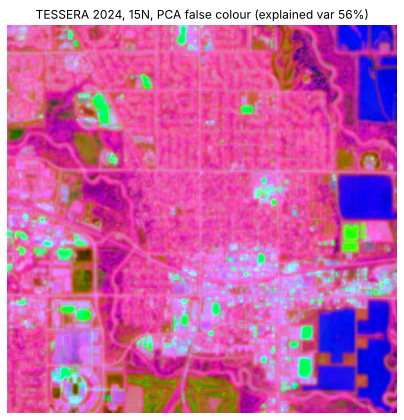

In [14]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})


def fit_pca(emb: np.ndarray, n_components: int = 3, max_samples: int = 200_000, seed: int = 0) -> PCA:
    flat = emb.reshape(-1, emb.shape[-1])
    ok = np.isfinite(flat).all(axis=1)
    flat = flat[ok]
    if len(flat) > max_samples:
        rng = np.random.default_rng(seed)
        flat = flat[rng.choice(len(flat), max_samples, replace=False)]
    return PCA(n_components=n_components, random_state=seed).fit(flat)


def to_rgb(emb: np.ndarray, pca: PCA, lo: float = 2, hi: float = 98) -> np.ndarray:
    rows, cols, d = emb.shape
    flat = emb.reshape(-1, d)
    ok = np.isfinite(flat).all(axis=1)
    out = np.zeros((flat.shape[0], 3), dtype=np.float32)
    comp = pca.transform(flat[ok])
    for k in range(3):
        a, b = np.percentile(comp[:, k], [lo, hi])
        comp[:, k] = np.clip((comp[:, k] - a) / max(b - a, 1e-6), 0, 1)
    out[ok] = comp
    return out.reshape(rows, cols, 3)


pca = fit_pca(emb24)
rgb24 = to_rgb(emb24, pca)

plt.figure(figsize=(7, 7))
plt.imshow(rgb24)
plt.title(f"TESSERA 2024, {AOI_ZONE.name}, PCA false colour (explained var {pca.explained_variance_ratio_.sum():.0%})")
plt.axis("off")
plt.show()

## 7. Application pattern B: "find me more like this" (similarity search)

Pick a reference pixel, compute cosine similarity to every other pixel in the window, and threshold. This is the building block for: finding all fields planted with the same crop as a known field, mapping a habitat type from one known occurrence, or flagging parcels that look like a reference set of damaged parcels after a storm.

The reference can be a single pixel or the mean of a labelled polygon. Means are more robust.

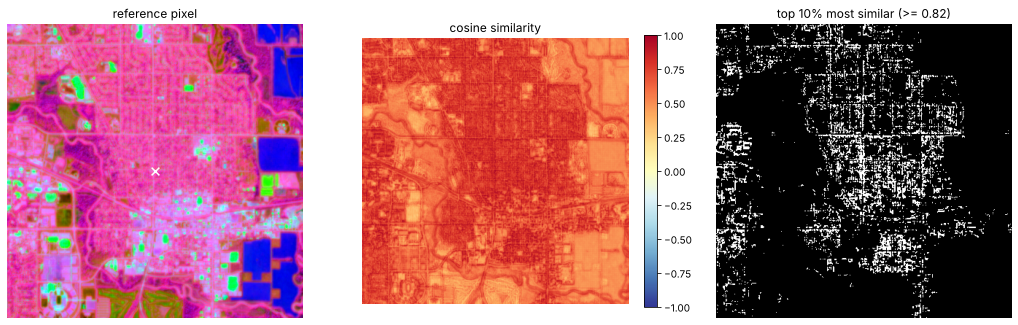

pixels above threshold: 16322  (~163 ha at 10 m)


In [15]:
def cosine_similarity_map(emb: np.ndarray, ref: np.ndarray) -> np.ndarray:
    rows, cols, d = emb.shape
    flat = emb.reshape(-1, d)
    ok = np.isfinite(flat).all(axis=1)
    sim = np.full(flat.shape[0], np.nan, dtype=np.float32)
    a = flat[ok]
    sim[ok] = (a @ ref) / (np.linalg.norm(a, axis=1) * np.linalg.norm(ref) + 1e-9)
    return sim.reshape(rows, cols)


# Reference: the centre pixel of the window (swap in any pixel or a polygon mean)
cy, cx = emb24.shape[0] // 2, emb24.shape[1] // 2
ref_vec = emb24[cy, cx]
if not np.isfinite(ref_vec).all():
    # fall back to the nearest valid pixel
    ok = np.isfinite(emb24).all(axis=-1)
    yy, xx = np.argwhere(ok)[0]
    cy, cx = int(yy), int(xx)
    ref_vec = emb24[cy, cx]

sim = cosine_similarity_map(emb24, ref_vec)
threshold = np.nanpercentile(sim, 90)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(rgb24); ax[0].scatter([cx], [cy], c="white", s=60, marker="x"); ax[0].set_title("reference pixel"); ax[0].axis("off")
im = ax[1].imshow(sim, vmin=-1, vmax=1, cmap="RdYlBu_r"); ax[1].set_title("cosine similarity"); ax[1].axis("off"); plt.colorbar(im, ax=ax[1], fraction=0.046)
ax[2].imshow(sim >= threshold, cmap="Greys_r"); ax[2].set_title(f"top 10% most similar (>= {threshold:.2f})"); ax[2].axis("off")
plt.show()

print(f"pixels above threshold: {int(np.nansum(sim >= threshold))}  (~{int(np.nansum(sim >= threshold)) * 0.01:.0f} ha at 10 m)")

## 8. Application pattern C: what changed between two years

Because every year sits on the same grid in the same CRS, change detection is a per-pixel distance between two embedding maps. v1.1 was specifically trained to be temporally stable, so a stable pixel has a small distance and a real change (clearing, flooding, construction, crop rotation) has a large one.

Use cosine distance rather than Euclidean when you want to be less sensitive to overall magnitude. Mask out pixels that were not valid in both years. Where a pixel has radar in one year and none in the other (much of the land in 2022 to 2024), the distance is inflated by about 0.13 to 0.25 with no real change, so also mask pixels whose radar presence (`s1_asc_obs_count + s1_desc_obs_count > 0`) differs between the two years; `read_bbox(..., with_counts=True)` returns the counts.

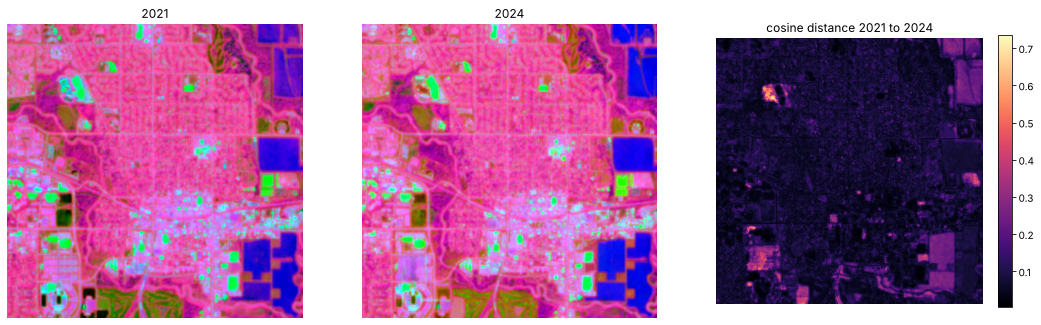

median distance 0.074, 95th pct 0.234
pixels flagged as changed (top 5%): 8161


In [16]:
YEAR_A, YEAR_B = 2021, 2024
embA, _, _, exA = reader.read_bbox(AOI_BBOX, YEAR_A)
embB, _, _, exB = reader.read_bbox(AOI_BBOX, YEAR_B)
assert embA.shape == embB.shape, "windows must align; they will on the same zone grid"


def cosine_distance_map(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    fa, fb = a.reshape(-1, a.shape[-1]), b.reshape(-1, b.shape[-1])
    ok = np.isfinite(fa).all(axis=1) & np.isfinite(fb).all(axis=1)
    out = np.full(fa.shape[0], np.nan, dtype=np.float32)
    num = (fa[ok] * fb[ok]).sum(axis=1)
    den = np.linalg.norm(fa[ok], axis=1) * np.linalg.norm(fb[ok], axis=1) + 1e-9
    out[ok] = 1.0 - num / den
    return out.reshape(a.shape[:2])


dist = cosine_distance_map(embA, embB)
change_thr = np.nanpercentile(dist, 95)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(to_rgb(embA, pca)); ax[0].set_title(f"{YEAR_A}"); ax[0].axis("off")
ax[1].imshow(to_rgb(embB, pca)); ax[1].set_title(f"{YEAR_B}"); ax[1].axis("off")
im = ax[2].imshow(dist, cmap="magma"); ax[2].set_title(f"cosine distance {YEAR_A} to {YEAR_B}"); ax[2].axis("off"); plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.show()

print(f"median distance {np.nanmedian(dist):.3f}, 95th pct {change_thr:.3f}")
print(f"pixels flagged as changed (top 5%): {int(np.nansum(dist >= change_thr))}")

A full nine-year trajectory for a single pixel is one line of code per year. This is how you would build a "field history" feature for a parcel-level app.

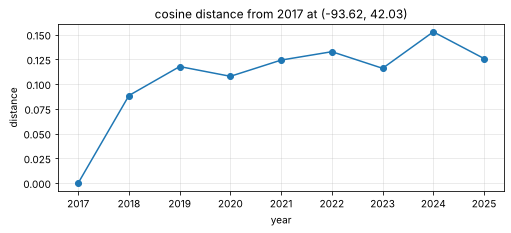

In [17]:
years = reader.years_complete(AOI_ZONE.name)
traj = {}
for y in years:
    vec, status, _ = reader.probe(AOI_LON, AOI_LAT, y)
    if vec is not None:
        traj[y] = vec

ys = sorted(traj)
if len(ys) >= 2:
    base = traj[ys[0]]
    drift = [1 - (traj[y] @ base) / (np.linalg.norm(traj[y]) * np.linalg.norm(base)) for y in ys]
    plt.figure(figsize=(8, 3))
    plt.plot(ys, drift, marker="o")
    plt.title(f"cosine distance from {ys[0]} at ({AOI_LON}, {AOI_LAT})")
    plt.xlabel("year"); plt.ylabel("distance"); plt.grid(alpha=0.3)
    plt.show()
else:
    print("fewer than two valid years at this point")

## 9. Application pattern D: few-shot land cover classification

This is where foundation-model embeddings earn their keep. A handful of labelled points per class and a linear classifier is often enough, because the heavy lifting already happened inside TESSERA. The paper reports state-of-the-art accuracy with small task heads on classification, segmentation, and regression tasks.

Below is the full loop: sample the embeddings at labelled points, fit a classifier, map the window. **The label table in it is a template.** Its rows are placeholder coordinates picked by hand to show the mechanics and never checked against the ground, so this section computes no accuracy, and its map shows only that the code runs. **Replace `LABELS` with your own points** (from a shapefile, a CSV of field surveys, or a GeoJSON you drew in QGIS). Labels do not need to be inside the window you classify; the model generalises across the zone and usually across regions.

**Filling `LABELS` from the USDA Cropland Data Layer (CDL).** The CDL is a national crop and land cover raster for each year. Download it for the area your labels come from and the same year (2024) from CropScape (https://nassgeodata.gmu.edu/CropScape/, which clips to a county or a drawn box) or as the national file (https://www.nass.usda.gov/Research_and_Science/Cropland/Release/index.php). Then sample 15 to 20 pixels across the classes, keeping only pixels whose 3 x 3 neighbourhood holds one class, so that no label sits on a field edge:

```python
import numpy as np, pandas as pd, rasterio
from pyproj import Transformer
from scipy.ndimage import maximum_filter, minimum_filter

CDL_CODES = {"cropland": [1, 5], "built": [121, 122, 123, 124], "water": [111], "woodland": [141, 142, 143]}
rng = np.random.default_rng(0)
rows = []
with rasterio.open("cdl_2024.tif") as src:                 # the CDL GeoTIFF you downloaded
    codes = src.read(1)
    uniform = minimum_filter(codes, 3) == maximum_filter(codes, 3)   # one class across 3 x 3: not an edge
    to_lonlat = Transformer.from_crs(src.crs, "EPSG:4326", always_xy=True)
    for label, values in CDL_CODES.items():
        r, c = np.nonzero(uniform & np.isin(codes, values))
        pick = rng.choice(len(r), size=min(5, len(r)), replace=False)
        xs, ys = rasterio.transform.xy(src.transform, r[pick], c[pick])
        rows += [(lon, lat, label) for lon, lat in zip(*to_lonlat.transform(xs, ys))]
LABELS = pd.DataFrame(rows, columns=["lon", "lat", "label"])
```

The codes are the CDL's (1 corn, 5 soybeans, 111 open water, 121 to 124 developed, 141 to 143 forest); check them against the legend of the year you download. This sketch was not run when this notebook was executed, because the CDL hosts could not be reached from there. Once the labels are real, score the classifier on points held out by location (whole fields or blocks rather than random points), since neighbouring pixels of one field are near duplicates.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# TEMPLATE: placeholder (lon, lat, class) rows that show the mechanics. They are not ground truth;
# replace them with real labelled points (see above) before you read anything into the map.
LABELS = pd.DataFrame([
    # cropland in the surrounding county
    (-93.70, 42.08, "cropland"), (-93.55, 42.10, "cropland"), (-93.75, 41.98, "cropland"), (-93.50, 41.95, "cropland"),
    (-93.68, 42.12, "cropland"), (-93.58, 41.92, "cropland"),
    # built-up (Ames campus and downtown)
    (-93.6465, 42.0266, "built"), (-93.6190, 42.0240, "built"), (-93.6300, 42.0350, "built"), (-93.6150, 42.0310, "built"),
    # water (Ada Hayden Lake, north of town)
    (-93.6230, 42.0725, "water"), (-93.6210, 42.0760, "water"), (-93.6260, 42.0700, "water"),
    # woodland / riparian along the Skunk River corridor
    (-93.5890, 42.0260, "woodland"), (-93.5910, 42.0150, "woodland"), (-93.5950, 42.0400, "woodland"),
], columns=["lon", "lat", "label"])

X_lab, prov_lab = reader.sample_points(list(zip(LABELS["lon"], LABELS["lat"])), year=2024)
ok = np.isfinite(X_lab).all(axis=1)
X_train, y_train = X_lab[ok], LABELS["label"].values[ok]
print(f"usable placeholder labels: {ok.sum()} of {len(LABELS)}")
print(pd.Series(y_train).value_counts().to_string())

clf = LogisticRegression(max_iter=2000, C=1.0)
clf.fit(X_train, y_train)

usable placeholder labels: 16 of 16
cropland    6
built       4
water       3
woodland    3


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

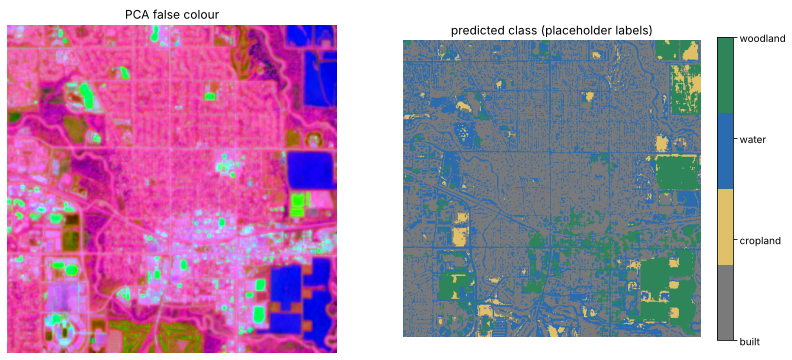

area by class (ha, from the placeholder labels): {'built': 916.7, 'cropland': 58.4, 'water': 450.2, 'woodland': 206.9}


In [19]:
def predict_map(model, emb: np.ndarray):
    rows, cols, d = emb.shape
    flat = emb.reshape(-1, d)
    ok = np.isfinite(flat).all(axis=1)
    pred = np.full(flat.shape[0], -1, dtype=np.int16)
    classes = list(model.classes_)
    labels = model.predict(flat[ok])
    pred[ok] = [classes.index(l) for l in labels]
    return pred.reshape(rows, cols), classes


pred_map, classes = predict_map(clf, emb24)

from matplotlib.colors import ListedColormap
COLOURS = {"cropland": "#e0c068", "built": "#7a7a7a", "water": "#2b6cb0", "woodland": "#2f855a"}
palette = ListedColormap([COLOURS.get(c, "#bbbbbb") for c in classes])   # classes_ is sorted: map by name
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].imshow(rgb24); ax[0].set_title("PCA false colour"); ax[0].axis("off")
masked = np.ma.masked_where(pred_map < 0, pred_map)
im = ax[1].imshow(masked, cmap=palette, vmin=0, vmax=len(classes) - 1); ax[1].set_title("predicted class (placeholder labels)"); ax[1].axis("off")
cbar = plt.colorbar(im, ax=ax[1], ticks=range(len(classes)), fraction=0.046); cbar.ax.set_yticklabels(classes)
plt.show()

areas = {c: float((pred_map == i).sum()) * 0.01 for i, c in enumerate(classes)}   # hectares at 10 m
print("area by class (ha, from the placeholder labels):", {k: round(v, 1) for k, v in areas.items()})

**Scaling this up.** For a county or a state, do not read the whole region into memory. Iterate over it in strips, predict each strip, and write each strip's prediction to disk as you go. The `geotessera` client exposes exactly this pattern as `iter_region`; with the Icechunk store you can do the same by stepping the `northing` slice in 512-row blocks. Keep each block aligned to 256-pixel chunk boundaries where you can so no chunk is fetched twice. `iter_region`'s strips start at the window top, so they are not chunk-aligned; `tessera_apps.io.iter_plan_blocks` streams chunk-aligned blocks.

## 10. Export to GeoTIFF for GIS

The window already carries a transform and a CRS, so writing a GeoTIFF is a few lines. Two exports are usually enough: the three-band PCA image for visual QA in QGIS, and the single-band prediction or change map as the actual product. Writing all 128 bands is also possible but a 400 x 400 window is already about 80 MB at float32 (20 MB as int8); store the int8 and scales separately if you need the raw vectors. The files go to `out/00_retrieval/` next to this notebook.

In [20]:
from pathlib import Path

import rasterio
from rasterio.transform import Affine

OUT_DIR = "out/00_retrieval"                    # next to this notebook
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)


def write_geotiff(path: str, array: np.ndarray, transform6: tuple, crs: CRS, nodata=None, dtype=None):
    """array: (rows, cols) or (rows, cols, bands). transform6: (a, b, c, d, e, f) as returned by read_bbox."""
    if array.ndim == 2:
        array = array[..., None]
    rows, cols, bands = array.shape
    dtype = dtype or array.dtype
    profile = dict(
        driver="GTiff", height=rows, width=cols, count=bands, dtype=dtype,
        crs=crs.to_wkt(), transform=Affine(*transform6), compress="deflate", tiled=True,
        blockxsize=256, blockysize=256,
    )
    if nodata is not None:
        profile["nodata"] = nodata
    with rasterio.open(path, "w", **profile) as dst:
        for b in range(bands):
            dst.write(array[..., b].astype(dtype), b + 1)
    return path


out_rgb = write_geotiff(f"{OUT_DIR}/tessera_2024_pca_rgb.tif", (rgb24 * 255).astype(np.uint8), transform, crs, dtype="uint8")
out_pred = write_geotiff(f"{OUT_DIR}/tessera_2024_landcover.tif", pred_map, transform, crs, nodata=-1, dtype="int16")
out_chg = write_geotiff(f"{OUT_DIR}/tessera_change_{YEAR_A}_{YEAR_B}.tif", np.nan_to_num(dist, nan=-1), transform, crs, nodata=-1, dtype="float32")
print("wrote:", out_rgb, out_pred, out_chg)

with rasterio.open(out_pred) as src:
    print(src.crs, src.transform, src.shape, "nodata", src.nodata)

wrote: out/00_retrieval/tessera_2024_pca_rgb.tif out/00_retrieval/tessera_2024_landcover.tif out/00_retrieval/tessera_change_2021_2024.tif
EPSG:32615 | 10.00, 0.00, 446650.00|
| 0.00,-10.00, 4655310.00|
| 0.00, 0.00, 1.00| (403, 405) nodata -1.0


## 11. Alternative access paths

### 11.1 More of the `geotessera` client

Section 1.2 covered the basics. Two more things the library does that are worth knowing: `read_patch` merges across UTM zone boundaries for you, which the hand-rolled `read_bbox` in Section 5 refuses to do; and on v2 stores, `GeoTesseraZarr(zarr_store_url("v2"))` with `depth=16` reads the first 16 matryoshka dimensions for an eighth of the bytes (v2 is a different model, so never mix its embeddings with these). The library also accepts any `zarr.abc.store.Store`, read as plain Zarr, and `cache_dir=` keeps a Zarr store's metadata and coordinate arrays on disk through zarr's `CacheStore`; chunk reads are cached in memory for the session only, and an Icechunk store ignores `cache_dir=` entirely. What its read calls do not return is the per-pixel observation counts and `years_complete`: the counts are only on the zone Dataset that `open_zone` returns, and a year missing from `years_complete` reads back as NaN without an error (`open_zone`'s Dataset does list such years, in `attrs["geotessera:years_incomplete"]`). That is why Section 5 exists.

In [21]:
# The client from Section 1.2, on the Icechunk store and checked as 1.1-dclimate
print("dataset:", gtz.dataset.name, "| url:", gtz.url)

vec_g, status_g = gtz.probe(AOI_LON, AOI_LAT, year=2024)
print("probe status:", status_g, " shape:", None if vec_g is None else vec_g.shape)

pts = gtz.sample_points([(AOI_LON, AOI_LAT), (0.12, 52.20)], year=2024)
print("sample_points:", pts.shape)

mosaic, tfm, crs_g = gtz.read_region(AOI_BBOX, year=2024)
print("read_region:", mosaic.shape, crs_g)
print("same values as read_bbox in Section 5.3:", mosaic.shape == emb24.shape and np.array_equal(mosaic, emb24, equal_nan=True))

# A fixed-size patch centred on a point, merged across UTM zones when needed
patch, tfm_p, crs_p = gtz.read_patch(AOI_LON, AOI_LAT, year=2024, size_px=256)
print("read_patch:", patch.shape)

dataset: 1.1-dclimate | url: s3://tessera-embeddings/v1.1/dclimate.icechunk


probe status: valid  shape: (128,)


sample_points: (2, 128)


read_region: (403, 405, 128) EPSG:32615
same values as read_bbox in Section 5.3: True


read_patch: (256, 256, 128)


### 11.2 Plain Zarr v3 on Source Coop (no Icechunk)

The same v1.1 embeddings are mirrored as plain Zarr. Note three differences: groups are named `utm01` to `utm60` and cover both hemispheres, the spatial coordinates are `x` and `y`, and `embeddings` is ordered `(time, band, y, x)` rather than band-last. Plain HTTPS cannot list a directory, so over HTTPS pass `consolidated=True`; with `consolidated=False` use the `s3://` form. The cell reads the copy from Source Coop's own bucket, `us-west-2.opendata.source.coop`, as `geotessera` does by default; through the `data.source.coop` gateway in front of it, the same objects are at `s3://tessera/tessera/zarr/v1.1-dclimate` with `endpoint_url="https://data.source.coop"`. It first checks that the bucket answers, and says so if it does not.

In [22]:
import urllib.error
import urllib.request

SC_BUCKET = "us-west-2.opendata.source.coop"        # Source Coop's bucket; data.source.coop is a gateway in front of it
SC_HTTPS = f"https://s3.us-west-2.amazonaws.com/{SC_BUCKET}"
SC_PATH = "tessera/tessera/zarr/v1.1-dclimate"
try:
    urllib.request.urlopen(urllib.request.Request(f"{SC_HTTPS}/{SC_PATH}/zarr.json", method="HEAD"), timeout=20).close()
    reachable = True
except urllib.error.HTTPError:
    reachable = True              # the host answered, if only with an HTTP error status
except OSError:
    reachable = False

if not reachable:
    print(f"Source Coop's bucket ({SC_HTTPS}) could not be reached from where this notebook was run, so no dataset is shown.")
else:
    try:
        ds_sc = xr.open_zarr(
            f"s3://{SC_BUCKET}/{SC_PATH}",
            group=f"utm{AOI_ZONE.number:02d}",
            storage_options={"anon": True, "client_kwargs": {"region_name": "us-west-2"}},
            consolidated=False, chunks=None,
        )
        print(ds_sc)
    except ImportError:
        print("This cell needs s3fs, the optional install in Section 1: %pip install s3fs")

<xarray.Dataset> Size: 199TB
Dimensions:                (time: 9, y: 1826816, x: 69632, month: 12,
                            band: 128, bnds: 2)
Coordinates:
  * time                   (time) int32 36B 2017 2018 2019 ... 2023 2024 2025
  * y                      (y) float64 15MB 9.339e+06 9.339e+06 ... -8.929e+06
  * x                      (x) float64 557kB 1.638e+05 1.639e+05 ... 8.602e+05
  * month                  (month) int16 24B 1 2 3 4 5 6 7 8 9 10 11 12
  * band                   (band) int32 512B 0 1 2 3 4 5 ... 123 124 125 126 127
Dimensions without coordinates: bnds
Data variables:
    s1_asc_month_covered   (time, y, x, month) bool 14TB ...
    embeddings             (time, band, y, x) int8 147TB ...
    time_bnds              (time, bnds) datetime64[ns] 144B ...
    scales                 (time, y, x) float32 5TB ...
    s1_desc_month_covered  (time, y, x, month) bool 14TB ...
    s1_desc_obs_count      (time, y, x) uint16 2TB ...
    s2_month_covered       (time, y, x, 

### 11.3 Tile downloads for offline work

`geotessera download --bbox "min_lon,min_lat,max_lon,max_lat" --year 2024 -o ./tiles` streams the box from the Zarr store and writes one float32 GeoTIFF per UTM zone (`tessera_2024_utmNN.tif`) on the native grid; add `--store-url s3://tessera-embeddings/v1.1/dclimate.icechunk` to read the store this notebook reads, and `--dry-run` to see the size first. `--format npy` still downloads 0.1-degree tiles, which the library has deprecated. `geotessera coverage --country "United States"` renders a coverage map. See the geotessera README for the full CLI.

### 11.4 Generating your own embeddings

If you need a non-calendar window (a growing season, say), a custom pixel size, or an area the global store did not fill, `tessera-embeddings` runs the same pipeline on one area of interest from a GeoJSON polygon, on a laptop in minutes for a few square kilometres. See `docs/quickstart.md` and `docs/single-vs-global.md` in the repository. Be aware that the single-area path and the global campaign use different default quality settings, so the same pixel can differ between the two.

## 12. From notebook to application

### 12.1 The cost model you must design around

| Operation | Bytes from S3 | Typical latency (warm session) |
|---|---|---|
| Open repository and session | tens of KB | under 1 s |
| Open a zone group with xarray | metadata plus coordinate arrays | a few seconds, once |
| One pixel (embeddings + scales) | about 8.1 MB on the wire (8.65 MB decoded), one chunk of each | 0.2 to 0.5 s in us-west-2, longer from elsewhere |
| 256 x 256 window | same as one pixel if chunk-aligned | similar |
| 4 km x 4 km window (400 x 400) | 4 to 9 chunks, about 32 to 73 MB | a few seconds |
| Whole zone with Dask chunking | do not | do not |

Rules that follow from this:

1. **Open once, read many.** Construct `TesseraReader` at process start and share it. Never reopen a zone per request.
2. **Batch points by chunk.** Points within the same 256 x 256 chunk cost one fetch. Sort incoming points by zone, then by `(northing // 2560, easting // 2560)`, and the reads collapse.
3. **Cache aggressively.** Within one snapshot, embeddings for a given pixel-year never change, but the `main` branch still takes commits (the infill updates in Section 2), so key a local disk cache by snapshot as well: `(snapshot_id, zone, year, chunk_row, chunk_col)` turns repeat requests into zero network calls. `geotessera`'s `cache_dir=` is not such a cache: for a Zarr store it keeps metadata and coordinate arrays on disk and chunk reads in memory for the session only, and an Icechunk store ignores it. `tessera_apps.cache.ChunkCache` is a persistent chunk cache for the Icechunk store, keyed by snapshot.
4. **Precompute what you serve.** If your product is a land cover map or a change map for a fixed region, compute it once, write the GeoTIFF or a COG, and serve that. Reserve live reads for interactive, point-level queries.
5. **Check `years_complete` on startup**, not per request, and surface the gap to the user rather than returning NaNs silently.

### 12.2 A minimal API

Here is a complete FastAPI service that exposes three operations: `probe` for a point and year, `trajectory` for the full history of a point, and `similarity` for two points in one year. The cell writes it to `out/00_retrieval/app.py`; run `uvicorn app:app --reload` from that folder. The `TesseraReader` class and what it uses from this notebook go in a `tessera_io.py` next to it: the `STORE_BUCKET`, `STORE_PREFIX` and `STORE_REGION` constants, the `Zone` dataclass, `zone_for`, `zone_attrs`, `year_label`, `probe`, `_ordered_slice` and `read_bbox`, with the imports of Section 1.

In [23]:
FASTAPI_APP = '''
from fastapi import FastAPI, HTTPException, Query
from pydantic import BaseModel
import numpy as np

from tessera_io import TesseraReader

app = FastAPI(title="TESSERA point service", version="0.1")
reader = TesseraReader()          # opened once, shared across requests


class Probe(BaseModel):
    lon: float
    lat: float
    year: int
    zone: str
    status: str
    s2_obs: int | None = None
    s1_asc_obs: int | None = None
    s1_desc_obs: int | None = None
    embedding: list[float] | None = None


@app.get("/probe", response_model=Probe)
def probe(lon: float = Query(..., ge=-180, le=180), lat: float = Query(..., ge=-90, le=90),
          year: int = Query(2024, ge=2017, le=2025), include_vector: bool = True):
    vec, status, prov = reader.probe(lon, lat, year)
    return Probe(
        lon=lon, lat=lat, year=year, zone=prov.get("zone", ""), status=status,
        s2_obs=prov.get("s2_obs"), s1_asc_obs=prov.get("s1_asc_obs"), s1_desc_obs=prov.get("s1_desc_obs"),
        embedding=(vec.tolist() if (vec is not None and include_vector) else None),
    )


@app.get("/trajectory")
def trajectory(lon: float, lat: float):
    from tessera_io import zone_for
    z = zone_for(lon, lat)
    out = []
    for y in reader.years_complete(z.name):
        vec, status, prov = reader.probe(lon, lat, y)
        out.append({"year": y, "status": status, "s2_obs": prov.get("s2_obs"),
                    "norm": (float(np.linalg.norm(vec)) if vec is not None else None)})
    return {"zone": z.name, "years": out}


@app.get("/similarity")
def similarity(lon_a: float, lat_a: float, lon_b: float, lat_b: float, year: int = 2024):
    a, sa, _ = reader.probe(lon_a, lat_a, year)
    b, sb, _ = reader.probe(lon_b, lat_b, year)
    if a is None or b is None:
        raise HTTPException(404, f"no data: a={sa}, b={sb}")
    cos = float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
    return {"year": year, "cosine_similarity": cos}
'''

with open(f"{OUT_DIR}/app.py", "w") as f:
    f.write(FASTAPI_APP)
print(f"wrote {OUT_DIR}/app.py  (run from there: pip install fastapi uvicorn && uvicorn app:app --reload)")

wrote out/00_retrieval/app.py  (run from there: pip install fastapi uvicorn && uvicorn app:app --reload)


### 12.3 Ideas the community can build with exactly these pieces

- **Parcel monitoring dashboard.** For a set of field polygons, store the per-year mean embedding and show cosine drift year over year. Flag parcels whose drift exceeds the regional 95th percentile.
- **Crop type mapper for a county.** Label 20 to 50 points per crop from a public survey, train the logistic regression in Section 9, run `iter_region`-style strips over the county, publish a COG.
- **Post-event damage screening.** After a named peril event (flood, hurricane, wildfire), compare the event year to the prior year across the affected footprint and rank parcels by change. Combine with the radar count layers to avoid flagging optical-only pixels as changed.
- **Habitat and natural capital baselines.** Similarity search from a few confirmed occurrences of a habitat type to map candidate extent, then validate in the field.
- **Data products for dClimate.** Aggregate any of the above to a grid or admin boundary and publish as a dataset the rest of the community can consume without touching the raw store.

Every one of these is: open the store, read a window or a point list, do linear algebra, write a raster or a table. None of them needs a GPU.

## 13. Working on this with Claude

The fastest way to extend this notebook is to install the `geotessera` agent skill (Section 1.1), give Claude the repository and this file as context, then ask for one concrete change at a time. With the skill loaded, Claude already knows the library's method signatures and conventions, so prompts can stay short and say what you want rather than how to call the API.

**Give it the right context.** Point Claude at `docs/global-store.md`, `docs/single-vs-global.md` and `README.md` in `dClimate/tessera-embeddings`, plus this notebook. Those documents contain everything about the store layout, the time convention, and the coverage caveats.

**Prompts that work well.**

- "Using the `TesseraReader` in this notebook, write a function that takes a GeoJSON FeatureCollection of polygons and returns the mean 2024 embedding per feature, reading each polygon's bounding box once and masking with `rasterio.features.rasterize`."
- "Extend `read_bbox` to handle a bounding box that crosses a UTM zone boundary by splitting it at the boundary, reading each half, and reprojecting the smaller half onto the larger half's grid with `rasterio.warp.reproject`."
- "Rewrite Section 9 to pull training labels from the USDA Cropland Data Layer for the same bounding box and year, then report a confusion matrix on a held-out set."
- "Add a disk cache to `TesseraReader` keyed by `(snapshot_id, zone, year, chunk_row, chunk_col)` so repeated point reads inside the same 256 x 256 chunk do not hit S3."
- "Turn the FastAPI app in Section 12 into a Streamlit page with a map click that returns the trajectory plot from Section 8."

**Things to tell Claude explicitly, because they are easy to get wrong.**

- `chunks=None` when opening a zone. Always.
- Check `scales` for `NaN` to detect no-data. Never treat a zero embedding as valid.
- Check `years_complete` before reading a year. A missing year is a publication gap, not an empty year.
- Zone groups are named `15N`, not `utm15`, and EPSG is 326xx north, 327xx south.
- `northing` is always descending; build slices accordingly.
- Zones are pure six-degree bands; do not apply MGRS exceptions for Norway and Svalbard.

## 14. Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `Repository.open` says the repository uses the Icechunk v2 format | icechunk 1.x | `pip install "icechunk>=2.2,<3"` |
| `gtz.dataset.name` is not `1.1-dclimate` | `geotessera` before 0.11 | `pip install "geotessera>=0.11,<0.12"` and pass the store URL as in Section 1.2 |
| `gtz.url` is the Source Coop URL | `GeoTesseraZarr()` called without `store_url` | Pass `store_url` as in Section 1.2 |
| `Repository.open` fails with a credentials error | `anonymous=True` not passed, or an old icechunk that does not accept it | Upgrade icechunk; keep `anonymous=True` |
| Codec error mentioning `pcodec` when reading `scales` | `numcodecs[pcodec]` not installed | `pip install "numcodecs[pcodec]"` |
| Opening a zone takes minutes and eats memory | Dask chunking on | Pass `chunks=None` |
| Every value is `NaN` | Pixel not embedded, or year not in `years_complete` | Check `scales`, check `years_complete`, try a neighbouring year |
| `.sel` with a slice returns an empty array | Slice bounds in the wrong order for a descending coordinate | Use `_ordered_slice` from Section 5.3 |
| Results differ from embeddings you generated yourself | Different default quality settings between single-area and global paths | See `docs/single-vs-global.md`; it is expected |
| Seams or slanted stripes in a window | Satellite orbit geometry, inherent to the raw data | Minimal effect on downstream tasks; known and documented |
| Source Coop open returns an empty dataset | HTTPS with `consolidated=False` (plain HTTPS cannot list a directory) | Pass `consolidated=True` over HTTPS, or use the `s3://` form in Section 11.2 |

## 15. Citing and contributing

If you publish work built on these embeddings, cite the TESSERA paper:

```
@misc{feng2025tessera,
  title  = {TESSERA: Temporal Embeddings of Surface Spectra for Earth Representation and Analysis},
  author = {Feng, Zhengpeng and Atzberger, Clement and Jaffer, Sadiq and Knezevic, Jovana and
            Sormunen, Silja and Young, Robin and Lisaius, Madeline C and Immitzer, Markus and
            Coomes, David A. and Madhavapeddy, Anil and Blake, Andrew and Keshav, Srinivasan},
  year   = {2025}, eprint = {2506.20380}, archivePrefix = {arXiv}, url = {https://arxiv.org/abs/2506.20380}
}
```

and acknowledge the data as "TESSERA v1.1 global embeddings, dClimate and University of Cambridge, hosted by the AWS Open Data Sponsorship Program, accessed on DATE from https://registry.opendata.aws/tessera".

Bugs in this notebook and ideas for new application patterns: open an issue or a pull request on `dClimate/tessera-embeddings`. Questions about the data itself go to the `ucam-eo/geotessera` issue tracker. Missing years or regions can be requested there as well.